In [1]:
import os, urllib.request, zipfile

if not os.path.exists('winequality-white.csv'):
    urllib.request.urlretrieve('https://archive.ics.uci.edu/static/public/186/wine+quality.zip',
                               'wine_quality.zip')
    zipfile.ZipFile('wine_quality.zip').extractall('.')

if not os.path.exists('UCI HAR Dataset'):
    urllib.request.urlretrieve('https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip',
                               'har.zip')
    zipfile.ZipFile('har.zip').extractall('.')
    zipfile.ZipFile('UCI HAR Dataset.zip').extractall('.') 

print('Wine file found :', os.path.exists('winequality-white.csv'))
print('HAR folder found:', os.path.exists('UCI HAR Dataset'))

Wine file found : True
HAR folder found: True


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal, skew

np.set_printoptions(suppress=True)

In [3]:
def standardize(X):
    return (X - np.mean(X, axis=0)) / np.std(X, axis=0)


def fit_gaussian_classifier(X, y, alpha):
    classes = np.unique(y)
    d = X.shape[1]
    params = []
    print('class    Nc   prior    rank     lambda    cond(C)      cond(C_reg)')
    for c in classes:
        Xc = X[y == c]
        Nc = len(Xc)
        prior = Nc / len(y)                            
        mu = np.mean(Xc, axis=0)                   
        C = np.cov(Xc.T, bias=True)               
        rank = np.linalg.matrix_rank(C)
        lam = alpha * np.trace(C) / rank             
        C_reg = C + lam * np.eye(d)                 
        print(f'{c:>5} {Nc:>5}  {prior:.4f}  {rank:>5}  {lam:9.5f}  {np.linalg.cond(C):11.3e}  {np.linalg.cond(C_reg):11.3e}')
        params.append((c, prior, mu, C_reg))
    return params

def classify(X, params):
    scores = np.zeros((len(X), len(params)))
    for k in range(len(params)):
        c, prior, mu, C_reg = params[k]
        scores[:, k] = multivariate_normal.logpdf(X, mu, C_reg) + np.log(prior)
    classes = np.array([p[0] for p in params])
    return classes[np.argmax(scores, axis=1)]


def confusion_tables(D, y):
    classes = np.unique(y)
    K = len(classes)
    counts = np.zeros((K, K), dtype=int)
    for i in range(K):
        for j in range(K):
            counts[i, j] = np.sum((D == classes[i]) & (y == classes[j]))
    probs = counts / counts.sum(axis=0)               
    rows = ['D=' + str(c) for c in classes]
    cols = ['L=' + str(c) for c in classes]
    return pd.DataFrame(counts, index=rows, columns=cols), pd.DataFrame(np.round(probs, 3), index=rows, columns=cols)

def pca(Z, k=3):
    eigvals, eigvecs = np.linalg.eigh(np.cov(Z.T))
    order = np.argsort(eigvals)[::-1]                
    eigvals = eigvals[order]
    eigvecs = eigvecs[:, order]
    explained = eigvals[:k] / np.sum(eigvals)
    return Z @ eigvecs[:, :k], explained

def plot_pca(P, y, explained, names, title, filename):
    fig = plt.figure(figsize=(15, 6))
    ax1 = fig.add_subplot(1, 2, 1)
    ax2 = fig.add_subplot(1, 2, 2, projection='3d')
    classes = sorted(np.unique(y), key=lambda c: -np.sum(y == c))   
    for c in classes:
        idx = (y == c)
        ax1.scatter(P[idx, 0], P[idx, 1], s=4, alpha=0.5, label=names[c])
        ax2.scatter(P[idx, 0], P[idx, 1], P[idx, 2], s=4, alpha=0.5, label=names[c])
    ax1.set_xlabel('PC1 (' + str(round(explained[0] * 100, 1)) + '%)')
    ax1.set_ylabel('PC2 (' + str(round(explained[1] * 100, 1)) + '%)')
    ax1.set_title(title + ': first two principal components')
    ax1.legend(markerscale=3)
    ax1.grid(True)
    ax2.set_xlabel('PC1')
    ax2.set_ylabel('PC2')
    ax2.set_zlabel('PC3')
    ax2.set_title(title + ': first three principal components')
    plt.tight_layout()
    plt.savefig(filename, dpi=300)
    plt.show()

In [4]:
# ---------------- Part A: load the Wine Quality (white) data ----------------
wine = pd.read_csv('winequality-white.csv', sep=';')

X_wine = wine.drop(columns='quality').values
y_wine = wine['quality'].values
wine_features = list(wine.columns[:-1])

print('Samples:', X_wine.shape[0], '| Features:', X_wine.shape[1])
print('Samples per quality level:')
print(wine['quality'].value_counts().sort_index())
print()
print('Feature variances (very different scales):')
print(np.round(np.var(X_wine, axis=0), 5))

Samples: 4898 | Features: 11
Samples per quality level:
quality
3      20
4     163
5    1457
6    2198
7     880
8     175
9       5
Name: count, dtype: int64

Feature variances (very different scales):
[   0.71197    0.01016    0.01464   25.72052    0.00048  289.18367
 1805.71675    0.00001    0.0228     0.01302    1.51412]


In [5]:
# ---------------- Part A: fit the Gaussian classifier and classify ----------------
alpha = 0.01
Z_wine = standardize(X_wine)

params_wine = fit_gaussian_classifier(Z_wine, y_wine, alpha)
D_wine = classify(Z_wine, params_wine)

Pe_wine = np.mean(D_wine != y_wine)
counts_wine, probs_wine = confusion_tables(D_wine, y_wine)

print()
print('Error probability estimate =', round(Pe_wine, 4))
print()
print('Confusion matrix (counts), rows = decision, columns = true label:')
print(counts_wine)
print()
print('Confusion matrix P(D=i|L=j):')
print(probs_wine)

class    Nc   prior    rank     lambda    cond(C)      cond(C_reg)
    3    20  0.0041     11    0.03474    1.307e+03    4.103e+02
    4   163  0.0333     11    0.01363    1.544e+02    1.016e+02
    5  1457  0.2975     11    0.00993    2.180e+02    1.264e+02
    6  2198  0.4488     11    0.00937    1.106e+02    8.235e+01
    7   880  0.1797     11    0.00771    3.062e+02    1.674e+02
    8   175  0.0357     11    0.00886    5.423e+02    2.215e+02
    9     5  0.0010      4    0.01275    4.752e+18    2.554e+02

Error probability estimate = 0.5043

Confusion matrix (counts), rows = decision, columns = true label:
     L=3  L=4  L=5  L=6  L=7  L=8  L=9
D=3    8    3   10    2    0    0    0
D=4    2   39   48   28    2    0    0
D=5    3   70  805  461   27    3    0
D=6    4   39  435  909  193   47    0
D=7    2   11  158  782  647  110    0
D=8    1    1    1   16   11   15    0
D=9    0    0    0    0    0    0    5

Confusion matrix P(D=i|L=j):
      L=3    L=4    L=5    L=6    L=7  

In [6]:
print(pd.Series(np.round(skew(X_wine, axis=0), 2), index=wine_features))

fixed acidity           0.65
volatile acidity        1.58
citric acid             1.28
residual sugar          1.08
chlorides               5.02
free sulfur dioxide     1.41
total sulfur dioxide    0.39
density                 0.98
pH                      0.46
sulphates               0.98
alcohol                 0.49
dtype: float64


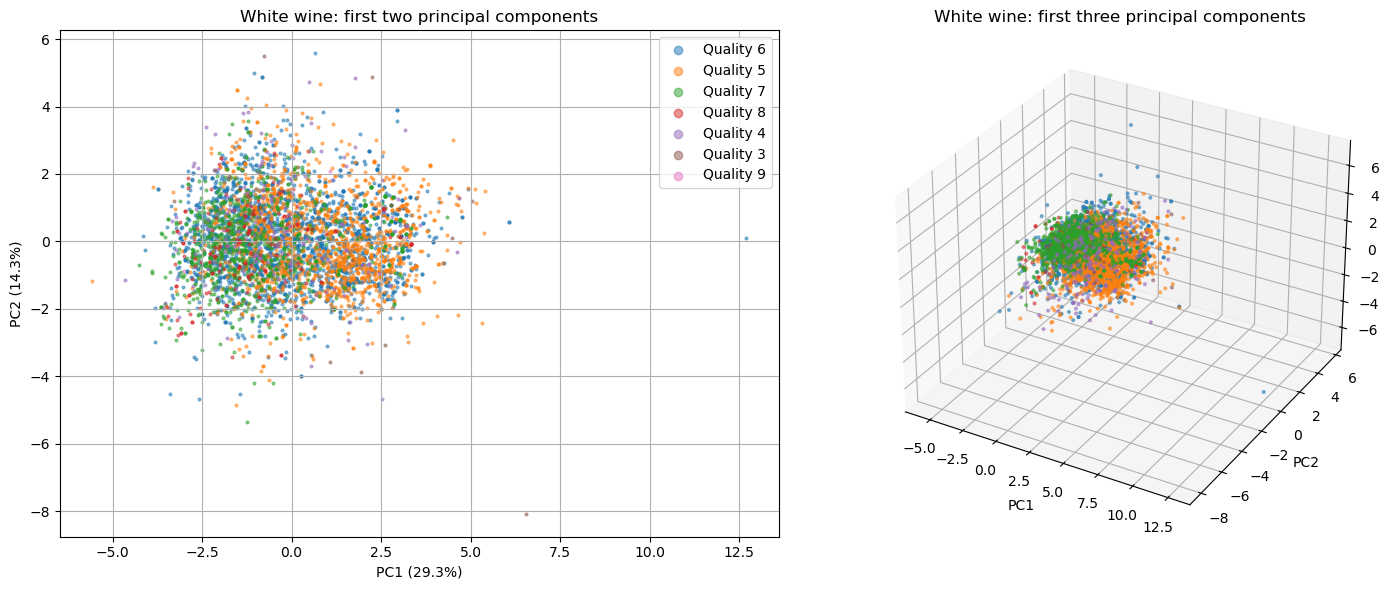

Variance explained by PC1-PC3: [29.3 14.3 11.1] %


In [7]:
# ---------------- Figure 1: PCA of the Wine data ----------------
P_wine, expl_wine = pca(Z_wine, 3)
wine_names = {q: 'Quality ' + str(q) for q in np.unique(y_wine)}
plot_pca(P_wine, y_wine, expl_wine, wine_names, 'White wine', 'Q3_Fig1_wine_PCA.png')
print('Variance explained by PC1-PC3:', np.round(expl_wine * 100, 1), '%')

In [8]:
# ---------------- Part B: load the Human Activity Recognition data ----------------
folder = 'UCI HAR Dataset/'
X_train = np.loadtxt(folder + 'train/X_train.txt')
y_train = np.loadtxt(folder + 'train/y_train.txt')
X_test  = np.loadtxt(folder + 'test/X_test.txt')
y_test  = np.loadtxt(folder + 'test/y_test.txt')

X_har = np.vstack([X_train, X_test])
y_har = np.concatenate([y_train, y_test]).astype(int)

har_names = {1: 'Walking', 2: 'Walking upstairs', 3: 'Walking downstairs',
             4: 'Sitting', 5: 'Standing', 6: 'Laying'}

print('Samples:', X_har.shape[0], '| Features:', X_har.shape[1])
for c in range(1, 7):
    print(c, har_names[c], ':', np.sum(y_har == c))

Samples: 10299 | Features: 561
1 Walking : 1722
2 Walking upstairs : 1544
3 Walking downstairs : 1406
4 Sitting : 1777
5 Standing : 1906
6 Laying : 1944


In [9]:
alpha = 0.01
Z_har = standardize(X_har)

params_har = fit_gaussian_classifier(Z_har, y_har, alpha)
D_har = classify(Z_har, params_har)

Pe_har = np.mean(D_har != y_har)
counts_har, probs_har = confusion_tables(D_har, y_har)

print()
print('Error probability estimate =', round(Pe_har, 4))
print()
print('Confusion matrix (counts), rows = decision, columns = true label:')
print(counts_har)
print()
print('Confusion matrix P(D=i|L=j):')
print(probs_har)

class    Nc   prior    rank     lambda    cond(C)      cond(C_reg)
    1  1722  0.1672    468    0.00735    5.827e+34    1.152e+04
    2  1544  0.1499    468    0.00648    1.834e+34    9.190e+03
    3  1406  0.1365    469    0.01214    1.490e+35    1.497e+04
    4  1777  0.1725    468    0.00380    5.206e+34    1.154e+04
    5  1906  0.1851    468    0.00322    1.927e+34    9.574e+03
    6  1944  0.1888    468    0.00496    2.473e+34    1.045e+04

Error probability estimate = 0.0652

Confusion matrix (counts), rows = decision, columns = true label:
      L=1   L=2   L=3   L=4   L=5   L=6
D=1  1717     0     2     0     0     0
D=2     5  1544   120     0     0     0
D=3     0     0  1284     0     0     0
D=4     0     0     0  1232     0     0
D=5     0     0     0   545  1906     0
D=6     0     0     0     0     0  1944

Confusion matrix P(D=i|L=j):
       L=1  L=2    L=3    L=4  L=5  L=6
D=1  0.997  0.0  0.001  0.000  0.0  0.0
D=2  0.003  1.0  0.085  0.000  0.0  0.0
D=3  0.000  0.0

In [10]:
sk_har = skew(X_har, axis=0)
print('Features with |skewness| > 1:', np.sum(np.abs(sk_har) > 1), 'out of', X_har.shape[1])
print('Median |skewness|:', round(np.median(np.abs(sk_har)), 2))

Features with |skewness| > 1: 271 out of 561
Median |skewness|: 0.93


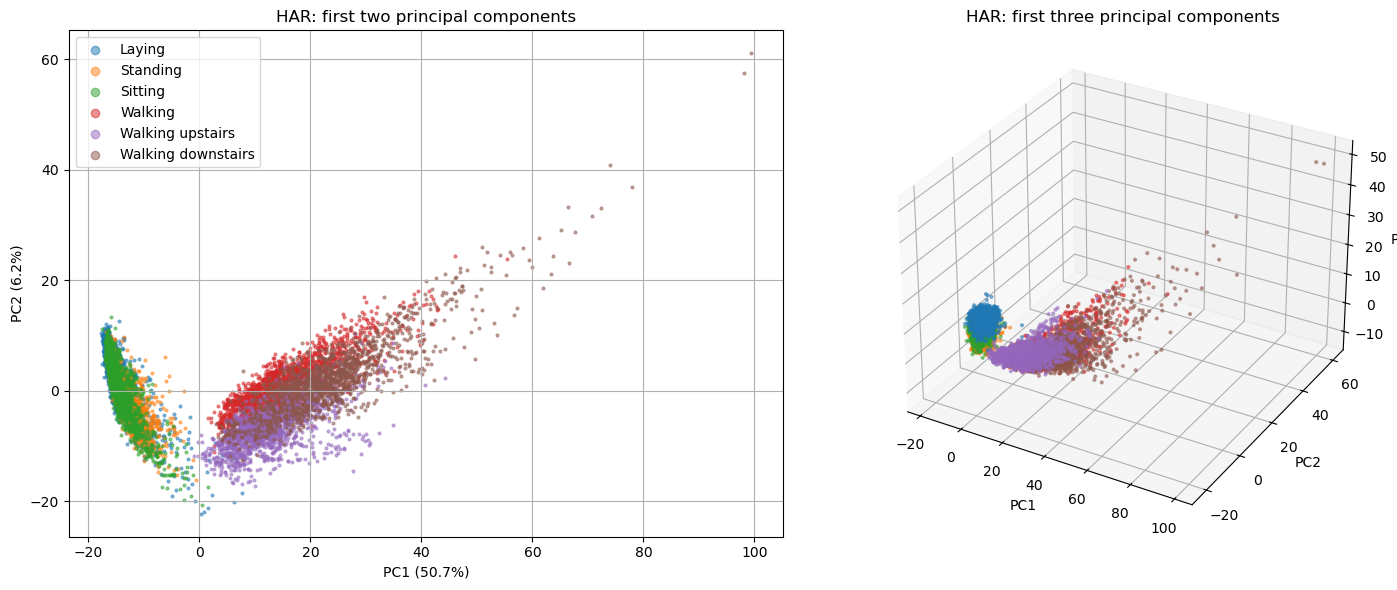

Variance explained by PC1-PC3: [50.7  6.2  2.7] %


In [11]:
P_har, expl_har = pca(Z_har, 3)
plot_pca(P_har, y_har, expl_har, har_names, 'HAR', 'Q3_Fig2_HAR_PCA.png')
print('Variance explained by PC1-PC3:', np.round(expl_har * 100, 1), '%')